# Cambodia Fire Data - Inspection & Preprocessing

**Scope of this notebook:** inspect both raw NASA FIRMS datasets, flag data-quality anomalies that
should NOT be silently ignored, then clean and merge the two sensors onto a common 5 km / weekly grid.
(Anomaly detection, prediction, and the web app come in a later notebook/app - this one is the
foundation both of those will read from.)

**Data sources (this folder):**
- `MODIS C6.1-Cambodia-2020-2025.csv` - MODIS, ~1 km resolution, Terra + Aqua.
- `SUOMI VIIRS C2-Cambodia-2020-2025.csv` - VIIRS, ~375 m resolution, Suomi-NPP.

**Study period:** 2020-01-01 to 2025-12-31 (6 full years).


## Step 1. Imports


In [1]:
import os
import warnings

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyproj import Transformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## Step 2. Load the raw datasets


In [2]:
MODIS_PATH = "MODIS C6.1-Cambodia-2020-2025.csv"
VIIRS_PATH = "SUOMI VIIRS C2-Cambodia-2020-2025.csv"

modis = pd.read_csv(MODIS_PATH)
viirs = pd.read_csv(VIIRS_PATH)

modis["acq_date"] = pd.to_datetime(modis["acq_date"])
viirs["acq_date"] = pd.to_datetime(viirs["acq_date"])

print("MODIS:", modis.shape, "| date range:", modis["acq_date"].min().date(), "to", modis["acq_date"].max().date())
print("VIIRS:", viirs.shape, "| date range:", viirs["acq_date"].min().date(), "to", viirs["acq_date"].max().date())
modis.head()


MODIS: (147097, 15) | date range: 2020-01-01 to 2025-12-31
VIIRS: (850813, 15) | date range: 2020-01-01 to 2025-12-31


,latitude,longitude,brightness,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_t31,frp,daynight,type
0,14.0508,103.2674,316.6,1.4,1.2,2020-01-01,400,Terra,MODIS,60,6.03,299.8,8.6,D,0
1,13.8760,104.3341,319.2,1.7,1.3,2020-01-01,400,Terra,MODIS,69,6.03,297.0,16.6,D,0
2,13.7107,105.3198,316.9,2.1,1.4,2020-01-01,400,Terra,MODIS,50,6.03,298.1,20.5,D,0
3,13.7076,105.3384,315.8,2.1,1.4,2020-01-01,400,Terra,MODIS,41,6.03,297.9,19.5,D,0
4,14.2023,104.4485,315.2,1.7,1.3,2020-01-01,400,Terra,MODIS,58,6.03,293.0,13.9,D,0


## Step 3. Data-quality inspection (look for unusual patterns BEFORE cleaning)


Goal: surface anything that looks like a sensor/processing artifact rather than a real fire, so cleaning
decisions below are based on evidence, not guesswork. We specifically check:
- Basic shape: duplicates, missing values, out-of-range coordinates.
- `type` column: FIRMS codes 0 = vegetation fire, 1 = volcano, 2 = other static land source, 3 = offshore.
  A legitimate static/non-fire source (volcano, gas flare, industrial heat source) should show up
  roughly **evenly across the year** (it is "static"), whereas real vegetation fires cluster tightly in
  the Nov-Apr dry season. If a non-zero `type` is instead *also* concentrated in the dry season, that is
  a sign that the type flag is not cleanly separating "real fire" from "static heat source" in this area.
- `version`: a changed processing/collection version mid-dataset can shift confidence scales and detection
  sensitivity - a silent version switch is a common hidden cause of a "fake" trend/anomaly in later steps.
- `confidence`: distribution and whether it shifts when `version` shifts.


In [3]:
print("Duplicate rows - MODIS:", modis.duplicated().sum())
print("Duplicate rows - VIIRS:", viirs.duplicated().sum())
print()
print("Missing values - MODIS:")
print(modis.isna().sum()[modis.isna().sum() > 0])
print("Missing values - VIIRS:")
print(viirs.isna().sum()[viirs.isna().sum() > 0])
print()
LAT_MIN, LAT_MAX = 10.4, 14.7
LON_MIN, LON_MAX = 102.3, 107.7
out_modis = ~(modis["latitude"].between(LAT_MIN, LAT_MAX) & modis["longitude"].between(LON_MIN, LON_MAX))
out_viirs = ~(viirs["latitude"].between(LAT_MIN, LAT_MAX) & viirs["longitude"].between(LON_MIN, LON_MAX))
print("Rows outside the Cambodia bounding box - MODIS:", out_modis.sum(), "| VIIRS:", out_viirs.sum())
print()
print("FRP <= 0 - MODIS:", (modis["frp"] <= 0).sum(), "| VIIRS:", (viirs["frp"] <= 0).sum())


Duplicate rows - MODIS: 0


Duplicate rows - VIIRS: 0

Missing values - MODIS:
Series([], dtype: int64)
Missing values - VIIRS:


Series([], dtype: int64)

Rows outside the Cambodia bounding box - MODIS: 0 | VIIRS: 1

FRP <= 0 - MODIS: 0 | VIIRS: 4


In [4]:
TYPE_LABELS = {0: "Vegetation fire", 1: "Volcano", 2: "Other static land source", 3: "Offshore"}

print("MODIS 'type' counts:")
print(modis["type"].map(TYPE_LABELS).value_counts())
print()
print("VIIRS 'type' counts:")
print(viirs["type"].map(TYPE_LABELS).value_counts())


MODIS 'type' counts:
type
Vegetation fire             146438
Other static land source       659
Name: count, dtype: int64

VIIRS 'type' counts:
type
Vegetation fire             849609
Other static land source       804
Offshore                       400
Name: count, dtype: int64


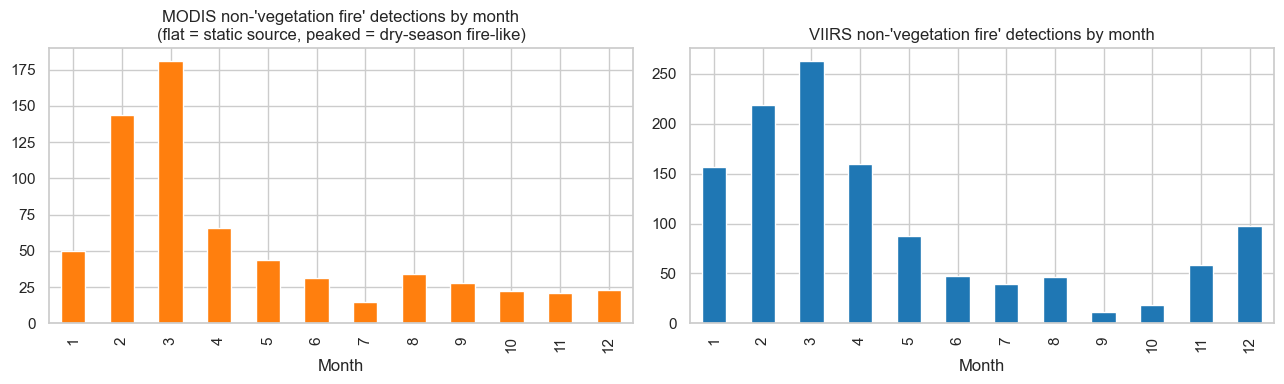

MODIS: 'other static land source' (type=2) detections by month:
acq_date
1      50
2     144
3     181
4      66
5      44
6      31
7      15
8      34
9      28
10     22
11     21
12     23
Name: count, dtype: int64

VIIRS: 'other static land source' (type=2) by month:
acq_date
1     129
2     134
3     133
4      80
5      56
6      25
7      25
8      45
9      11
10     17
11     54
12     95
Name: count, dtype: int64

VIIRS: 'offshore' (type=3) by month:
acq_date
1      28
2      85
3     130
4      80
5      32
6      22
7      14
8       1
10      1
11      4
12      3
Name: count, dtype: int64


In [5]:
# Does each non-vegetation-fire type cluster in the dry season (like real fires) or spread evenly
# across the year (consistent with a genuinely "static" non-fire source)?
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

modis_other = modis[modis["type"] != 0]
if len(modis_other):
    modis_other["acq_date"].dt.month.value_counts().sort_index().plot(
        kind="bar", ax=axes[0], color="tab:orange")
axes[0].set_title("MODIS non-'vegetation fire' detections by month\n(flat = static source, peaked = dry-season fire-like)")
axes[0].set_xlabel("Month")

viirs_other = viirs[viirs["type"] != 0]
viirs_other["acq_date"].dt.month.value_counts().sort_index().plot(
    kind="bar", ax=axes[1], color="tab:blue")
axes[1].set_title("VIIRS non-'vegetation fire' detections by month")
axes[1].set_xlabel("Month")
plt.tight_layout()
plt.show()

print("MODIS: 'other static land source' (type=2) detections by month:")
print(modis[modis["type"] == 2]["acq_date"].dt.month.value_counts().sort_index())
print()
print("VIIRS: 'other static land source' (type=2) by month:")
print(viirs[viirs["type"] == 2]["acq_date"].dt.month.value_counts().sort_index())
print()
print("VIIRS: 'offshore' (type=3) by month:")
print(viirs[viirs["type"] == 3]["acq_date"].dt.month.value_counts().sort_index())


**Finding:** no `type = 1` (volcano) rows exist in either file - expected, since Cambodia has no active
volcanoes; FIRMS correctly never assigns that code here, so there is nothing to clean for that code.

**Finding (the real anomaly):** MODIS `type = 2` and VIIRS `type = 2` / `type = 3` are **not** flat across
the year like a genuinely static source should be - they peak in Jan-Apr, the same dry-season window as
real vegetation fires. This means FIRMS' `type` classification is **not cleanly separating** "real fire"
from "other heat source" here; some of what gets labeled `type != 0` is plausibly still dry-season burning
(e.g. crop residue or land-clearing fires near a static feature such as a quarry/kiln) rather than a true
non-fire artifact. **Decision:** still exclude `type != 0` from the fire-activity dataset (it is the
documented FIRMS convention and the safer default), but this ambiguity is recorded here rather than
treated as a clean binary split - do not assume `type != 0` rows are automatically "junk" if you later
need high recall.


In [6]:
print("MODIS version values and coverage:")
print(modis.groupby("version")["acq_date"].agg(["min", "max", "count"]))
print()
print("MODIS confidence distribution, split by version:")
print(modis.groupby("version")["confidence"].describe()[["count", "mean", "std", "min", "50%", "max"]])


MODIS version values and coverage:
               min        max  count
version                             
6.03    2020-01-01 2022-12-31  79417
61.03   2023-01-01 2025-12-31  67680

MODIS confidence distribution, split by version:
           count       mean        std  min   50%    max
version                                                 
6.03     79417.0  65.279827  19.057353  0.0  68.0  100.0
61.03    67680.0  64.690337  18.786291  0.0  67.0  100.0


**Finding:** MODIS silently switches **processing version mid-dataset**: `6.03` covers 2020-01-01 to
2022-12-31, `61.03` covers 2023-01-01 to 2025-12-31 (NASA's Collection 6 -> Collection 6.1 reprocessing).
Confidence distributions are close enough (mean ~65 vs ~65, similar spread) that no extra rescaling is
applied here, but this is exactly the kind of change that can silently distort a multi-year trend or
anomaly baseline if ignored - noting it explicitly so later baseline/trend work can account for it if a
real discrepancy shows up. VIIRS has a single version (`2`) throughout, so no equivalent check is needed
there.


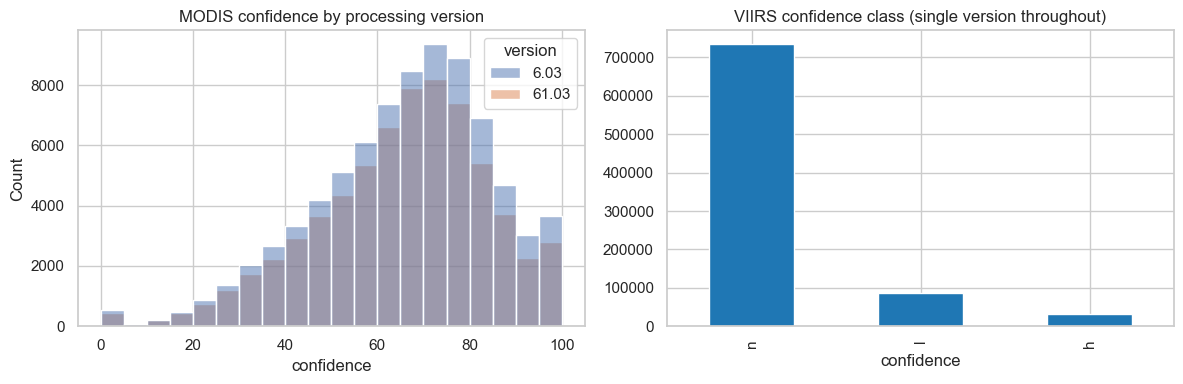

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
conf_df = pd.DataFrame({
    "confidence": pd.to_numeric(modis["confidence"], errors="coerce"),
    "version": modis["version"].astype(str),
})
sns.histplot(data=conf_df, x="confidence", hue="version", bins=20, ax=axes[0])
axes[0].set_title("MODIS confidence by processing version")
viirs["confidence"].astype(str).str.lower().value_counts().plot(kind="bar", ax=axes[1], color="tab:blue")
axes[1].set_title("VIIRS confidence class (single version throughout)")
plt.tight_layout()
plt.show()


## Step 4. Cleaning (decisions driven by the inspection above)


In [8]:
def basic_clean(df, name):
    df = df.copy()
    n_start = len(df)

    df["acq_date"] = pd.to_datetime(df["acq_date"], errors="coerce")
    for col in ["latitude", "longitude", "frp"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

    n_before = len(df)
    df = df.dropna(subset=["latitude", "longitude", "acq_date"])
    dropped_missing = n_before - len(df)

    n_before = len(df)
    df = df[df["latitude"].between(-90, 90) & df["longitude"].between(-180, 180)]
    dropped_range = n_before - len(df)

    n_before = len(df)
    df = df.drop_duplicates()
    dropped_dupes = n_before - len(df)

    # Keep only type = 0 (vegetation fire) - see Step 3 finding for the caveat on this choice
    n_before = len(df)
    df = df[df["type"] == 0]
    dropped_type = n_before - len(df)

    n_before = len(df)
    df = df[df["frp"] > 0]
    dropped_frp = n_before - len(df)

    print(f"{name}: {n_start} -> {len(df)} rows")
    print(f"  removed {dropped_missing} missing date/lat/lon, {dropped_range} out-of-range coords, "
          f"{dropped_dupes} duplicates, {dropped_type} non-vegetation-fire type, {dropped_frp} zero/negative FRP")
    return df.reset_index(drop=True)


modis_basic = basic_clean(modis, "MODIS")
viirs_basic = basic_clean(viirs, "VIIRS")

modis_basic["confidence"] = pd.to_numeric(modis_basic["confidence"], errors="coerce")
viirs_basic["confidence"] = viirs_basic["confidence"].astype(str).str.lower()


MODIS: 147097 -> 146438 rows
  removed 0 missing date/lat/lon, 0 out-of-range coords, 0 duplicates, 659 non-vegetation-fire type, 0 zero/negative FRP


VIIRS: 850813 -> 849605 rows
  removed 0 missing date/lat/lon, 0 out-of-range coords, 0 duplicates, 1204 non-vegetation-fire type, 4 zero/negative FRP


### 4.1 Confidence filtering (documented thresholds, not blind)


In [9]:
MODIS_MIN_CONFIDENCE = 30

before_m, before_v = len(modis_basic), len(viirs_basic)
modis_conf = modis_basic[modis_basic["confidence"] >= MODIS_MIN_CONFIDENCE].reset_index(drop=True)
viirs_conf = viirs_basic[viirs_basic["confidence"] != "l"].reset_index(drop=True)

print(f"MODIS: {before_m} -> {len(modis_conf)} (dropped {before_m - len(modis_conf)} with confidence < {MODIS_MIN_CONFIDENCE})")
print(f"VIIRS: {before_v} -> {len(viirs_conf)} (dropped {before_v - len(viirs_conf)} low-confidence 'l' detections)")


MODIS: 146438 -> 139871 (dropped 6567 with confidence < 30)
VIIRS: 849605 -> 763252 (dropped 86353 low-confidence 'l' detections)


## Step 5. Cambodia geographic filtering


No boundary polygon file is invented here. If a `cambodia_boundary.geojson` file (e.g. from
https://gadm.org, admin level 0) is placed in this folder, it is used automatically; otherwise this
falls back to the bounding box, with the known limitation that a rectangle also touches small border
areas of Thailand/Vietnam/Laos.


In [10]:
BOUNDARY_FILE = "cambodia_boundary.geojson"
cambodia_polygon = None
if os.path.exists(BOUNDARY_FILE):
    try:
        import geopandas as gpd
        cambodia_polygon = gpd.read_file(BOUNDARY_FILE).geometry.union_all()
        print(f"Using real boundary polygon from '{BOUNDARY_FILE}'.")
    except ImportError:
        print("geopandas/shapely not installed - falling back to bounding box.")
else:
    print(f"No '{BOUNDARY_FILE}' found - using bounding-box approximation (see limitation above).")


def filter_cambodia(df, name):
    n_before = len(df)
    if cambodia_polygon is not None:
        import geopandas as gpd
        gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df["longitude"], df["latitude"]), crs="EPSG:4326")
        df = df[gdf.geometry.within(cambodia_polygon)].reset_index(drop=True)
    else:
        df = df[df["latitude"].between(LAT_MIN, LAT_MAX) & df["longitude"].between(LON_MIN, LON_MAX)].reset_index(drop=True)
    print(f"{name}: {n_before} -> {len(df)} ({n_before - len(df)} removed)")
    return df


modis_clean = filter_cambodia(modis_conf, "MODIS")
viirs_clean = filter_cambodia(viirs_conf, "VIIRS")

start = max(modis_clean["acq_date"].min(), viirs_clean["acq_date"].min())
end = min(modis_clean["acq_date"].max(), viirs_clean["acq_date"].max())
modis_clean = modis_clean[modis_clean["acq_date"].between(start, end)].reset_index(drop=True)
viirs_clean = viirs_clean[viirs_clean["acq_date"].between(start, end)].reset_index(drop=True)
print("Common period:", start.date(), "to", end.date())
print("MODIS clean:", modis_clean.shape, "| VIIRS clean:", viirs_clean.shape)


No 'cambodia_boundary.geojson' found - using bounding-box approximation (see limitation above).
MODIS: 139871 -> 139871 (0 removed)


VIIRS: 763252 -> 763251 (1 removed)
Common period: 2020-01-01 to 2025-12-31
MODIS clean: (139871, 15) | VIIRS clean: (763251, 15)


## Step 6. Spatial and temporal aggregation (5 km grid, weekly)


In [11]:
transformer = Transformer.from_crs("EPSG:4326", "EPSG:32648", always_xy=True)
GRID_SIZE = 5000


def add_grid_and_week(df):
    x, y = transformer.transform(df["longitude"].values, df["latitude"].values)
    df = df.copy()
    df["grid_x"] = (x // GRID_SIZE).astype(int)
    df["grid_y"] = (y // GRID_SIZE).astype(int)
    df["grid_id"] = df["grid_x"].astype(str) + "_" + df["grid_y"].astype(str)
    df["week"] = df["acq_date"].dt.to_period("W").dt.start_time
    return df


modis_clean = add_grid_and_week(modis_clean)
viirs_clean = add_grid_and_week(viirs_clean)

modis_counts = modis_clean.groupby(["week", "grid_id"]).size().reset_index(name="MODIS")
viirs_counts = viirs_clean.groupby(["week", "grid_id"]).size().reset_index(name="VIIRS")
weekly = pd.merge(modis_counts, viirs_counts, on=["week", "grid_id"], how="outer")
weekly[["MODIS", "VIIRS"]] = weekly[["MODIS", "VIIRS"]].fillna(0).astype(int)
weekly = weekly.sort_values(["week", "grid_id"]).reset_index(drop=True)

print("Duplicate grid-week rows:", weekly.duplicated(subset=["week", "grid_id"]).sum())
print("Rows (week x grid):", len(weekly))
weekly.head()


Duplicate grid-week rows: 0
Rows (week x grid): 228615


,week,grid_id,MODIS,VIIRS
0,2019-12-30,100_267,0,1
1,2019-12-30,100_268,1,3
2,2019-12-30,100_269,1,1
3,2019-12-30,100_283,4,3
4,2019-12-30,100_284,0,1


## Step 7. Save cleaned outputs


In [12]:
os.makedirs("output", exist_ok=True)
keep_cols = ["acq_date", "latitude", "longitude", "frp", "confidence", "week", "grid_id"]
modis_clean[keep_cols].to_csv("output/modis_clean.csv", index=False)
viirs_clean[keep_cols].to_csv("output/viirs_clean.csv", index=False)
weekly.to_csv("output/weekly_grid.csv", index=False)
print(os.listdir("output"))


['modis_clean.csv', 'viirs_clean.csv', 'weekly_grid.csv']


## Summary of data-quality findings (for the write-up)

1. **No `type = 1` (volcano)** in either dataset - expected for Cambodia, nothing to clean.
2. **`type = 2`/`type = 3` are dry-season-clustered, not flat** - FIRMS' type code does not cleanly
   separate "static non-fire source" from "fire" here; excluded by convention, but flagged as an
   approximation rather than a guaranteed-clean split.
3. **MODIS silently switches processing version** (6.03 -> 61.03) at the 2022/2023 boundary - confidence
   distributions are similar enough that no rescaling was applied, but this is the kind of change to
   re-check if a multi-year trend/anomaly ever looks suspiciously sharp right at that boundary.
4. **No duplicates, no missing values, no out-of-bounds coordinates, no non-positive FRP survives
   cleaning** - the raw files are otherwise high quality.
